# Лабораторная работа №4
## По дисциплине Введение в машинное обучние
### Выполнил Цвиль Павел ФИТ-231

## Задание 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Задание 2.1. Изучение датасета")
df = pd.read_csv('howpop_train.csv')
print(df.head())
print("\nИнформация о столбцах:")
print(df.info())

Задание 2.1. Изучение датасета
                                url        domain  post_id  \
0  https://habrahabr.ru/post/18284/  habrahabr.ru    18284   
1  https://habrahabr.ru/post/18285/  habrahabr.ru    18285   
2  https://habrahabr.ru/post/18286/  habrahabr.ru    18286   
3  https://habrahabr.ru/post/18291/  habrahabr.ru    18291   
4  https://geektimes.ru/post/18294/  geektimes.ru    18294   

             published      author     flow polling content_len  \
0  2008-01-01 18:19:00      @Tapac  develop   False        4305   
1  2008-01-01 18:30:00  @DezmASter   design   False        7344   
2  2008-01-01 18:34:00  @DezmASter   design   False        8431   
3  2008-01-02 01:32:00    @Taoorus   design   False        5662   
4  2008-01-02 14:34:00    @dennydo      NaN   False        3706   

                                               title  comments  favs views  \
0     Новогодний подарок блоггерам — WordPress 2.3.2         0     0   236   
1  Сумасшедшие яйца, или сервис для о

C:\Users\pavel\AppData\Local\Temp\ipykernel_22016\2108015441.py:6: DtypeWarning: Columns (0: polling, 1: content_len, 2: views, 3: Unnamed: 17) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('howpop_train.csv')


In [4]:
print("Задание 2.2. Удаление столбцов, заканчивающихся на '_lognorm'")
# Используем встроенный filter для получения списка столбцов
cols_to_drop = list(filter(lambda c: c.endswith("_lognorm"), df.columns))
print(f"Удаляемые столбцы: {cols_to_drop}")

df.drop(cols_to_drop, axis=1, inplace=True)
print(f"Осталось столбцов: {df.shape[1]}")

Задание 2.2. Удаление столбцов, заканчивающихся на '_lognorm'
Удаляемые столбцы: ['views_lognorm', 'favs_lognorm', 'comments_lognorm']
Осталось столбцов: 16


In [5]:
print("Задание 2.3. Преобразование столбца 'published' в datetime")
df["published"] = pd.to_datetime(df.published, yearfirst=True)
print(df["published"].head())

Задание 2.3. Преобразование столбца 'published' в datetime
0   2008-01-01 18:19:00
1   2008-01-01 18:30:00
2   2008-01-01 18:34:00
3   2008-01-02 01:32:00
4   2008-01-02 14:34:00
Name: published, dtype: datetime64[us]


In [6]:
print("Задание 2.4. Создание столбцов: year, month, dayofweek, hour")
df["year"] = [d.year for d in df.published]
df["month"] = [d.month for d in df.published]
df["dayofweek"] = [d.isoweekday() for d in df.published]
df["hour"] = [d.hour for d in df.published]
print(df[["published", "year", "month", "dayofweek", "hour"]].head())

Задание 2.4. Создание столбцов: year, month, dayofweek, hour
            published  year  month  dayofweek  hour
0 2008-01-01 18:19:00  2008      1          2    18
1 2008-01-01 18:30:00  2008      1          2    18
2 2008-01-01 18:34:00  2008      1          2    18
3 2008-01-02 01:32:00  2008      1          3     1
4 2008-01-02 14:34:00  2008      1          3    14


Задание 2.5. Больше всего публикаций: в каком месяце и году


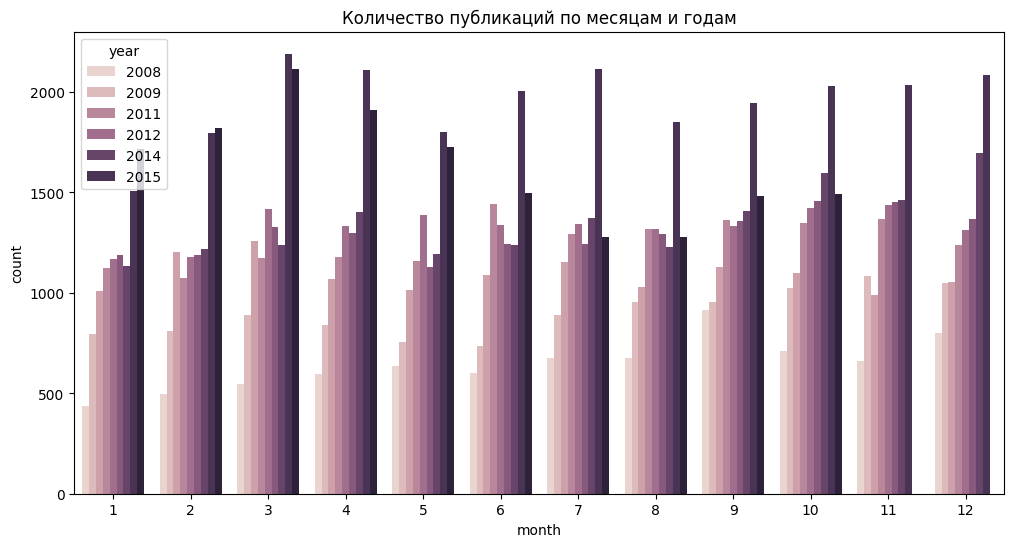

In [8]:
print("Задание 2.5. Больше всего публикаций: в каком месяце и году")
plt.figure(figsize=(12, 6))
sns.countplot(x='month', hue='year', data=df)
plt.title("Количество публикаций по месяцам и годам")
plt.show()

Задание 2.6. Зависимость числа публикаций от дня недели


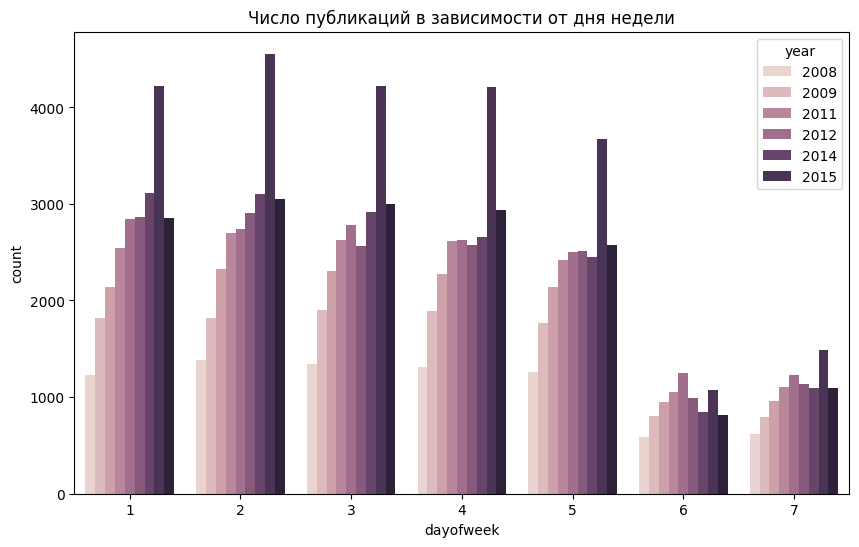

In [9]:
print("Задание 2.6. Зависимость числа публикаций от дня недели")
plt.figure(figsize=(10, 6))
sns.countplot(x='dayofweek', hue='year', data=df)
plt.title("Число публикаций в зависимости от дня недели")
plt.show()

Задание 2.7. Визуальный анализ (просмотры и комментарии по часам)


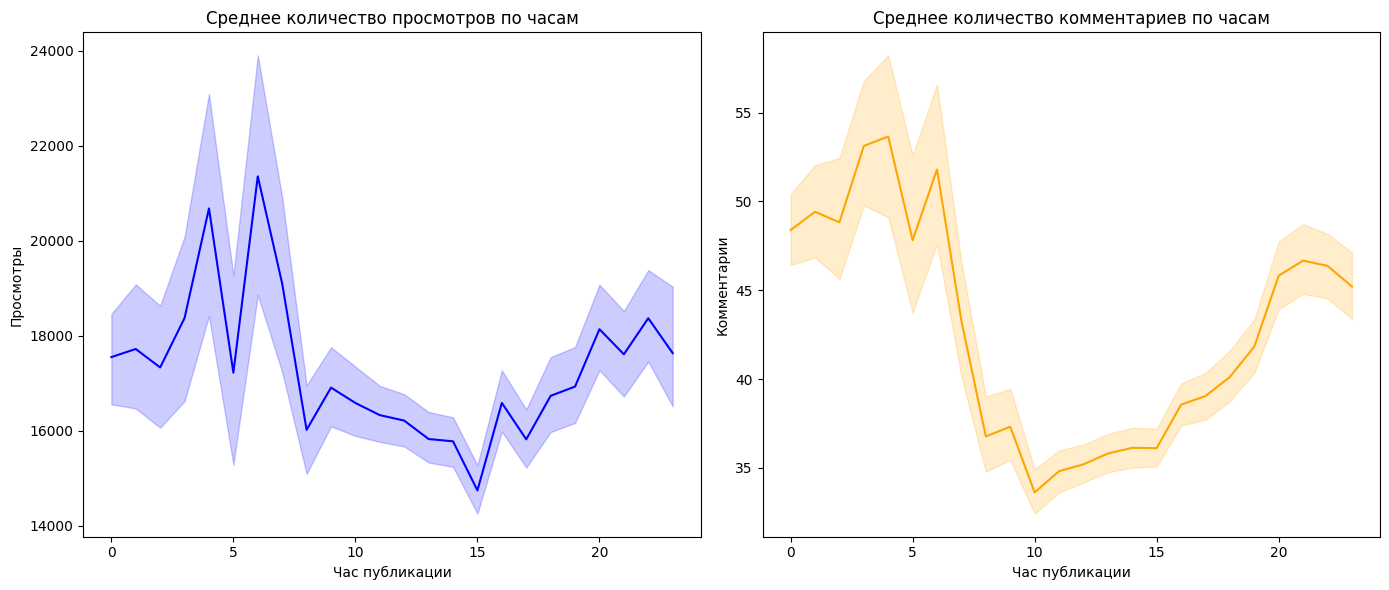

In [13]:
print("Задание 2.7. Визуальный анализ (просмотры и комментарии по часам)")

df['views'] = df['views'].astype(str).str.replace(',', '.').astype(float)
df['comments'] = df['comments'].astype(str).str.replace(',', '.').astype(float)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.lineplot(x='hour', y='views', data=df, color="blue")
plt.title("Среднее количество просмотров по часам")
plt.xlabel("Час публикации")
plt.ylabel("Просмотры")

plt.subplot(1, 2, 2)
sns.lineplot(x='hour', y='comments', data=df, color="orange")
plt.title("Среднее количество комментариев по часам")
plt.xlabel("Час публикации")
plt.ylabel("Комментарии")

plt.tight_layout()
plt.show()


Задание 2.8. Кого из топ-20 авторов чаще всего минусуют


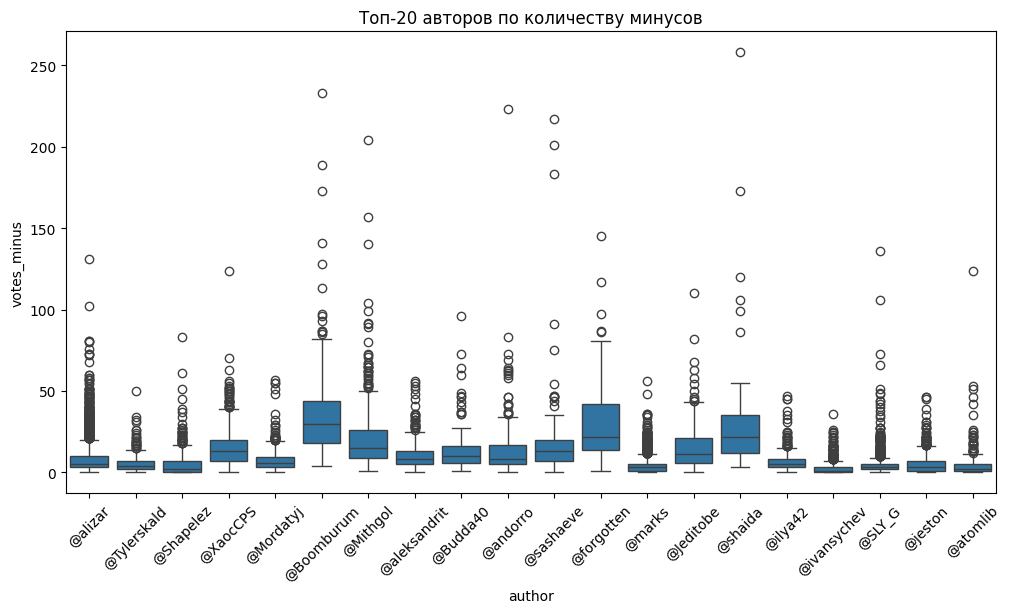

In [16]:
print("Задание 2.8. Кого из топ-20 авторов чаще всего минусуют")

df['votes_minus'] = df['votes_minus'].astype(str).str.replace(',', '.').astype(float)

top_authors = df.groupby("author")["votes_minus"].sum().nlargest(20).index

plt.figure(figsize=(12, 6))
sns.boxplot(x='author', y='votes_minus', data=df[df['author'].isin(top_authors)])
plt.xticks(rotation=45)
plt.title("Топ-20 авторов по количеству минусов")
plt.show()

Задание 2.9. Сравнение субботы и понедельника


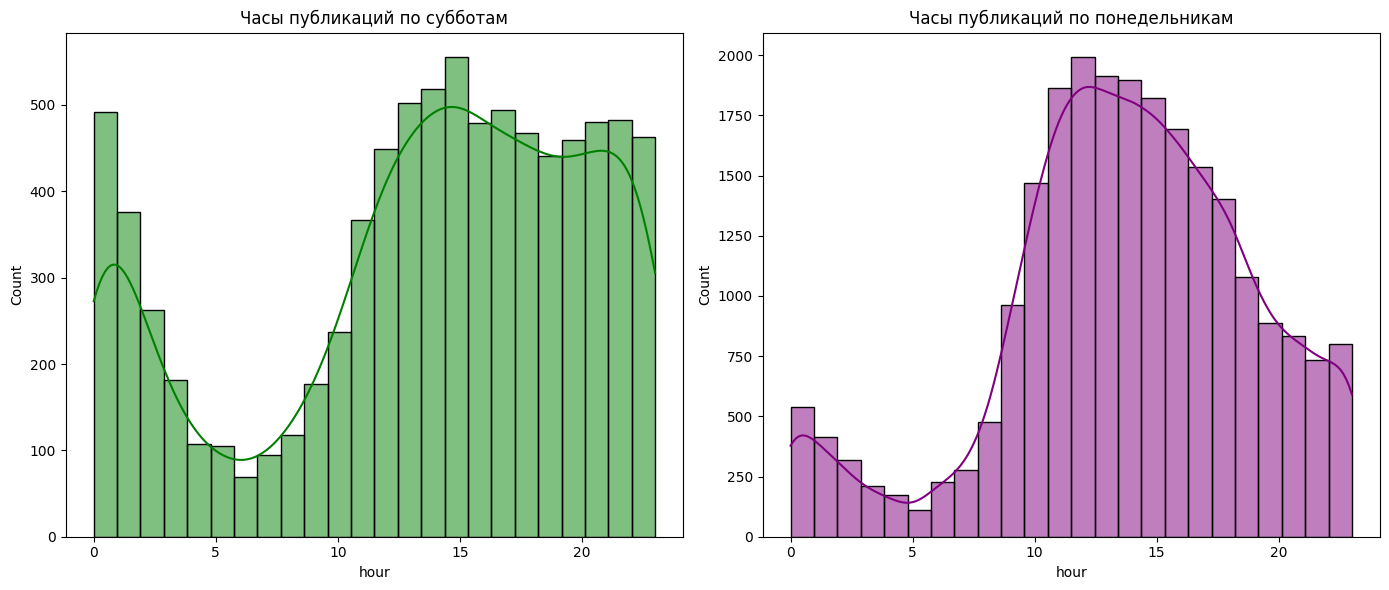

In [17]:
print("Задание 2.9. Сравнение субботы и понедельника")
saturday = df[df["dayofweek"] == 6]
monday = df[df["dayofweek"] == 1]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(saturday["hour"], bins=24, kde=True, color="green")
plt.title("Часы публикаций по субботам")

plt.subplot(1, 2, 2)
sns.histplot(monday["hour"], bins=24, kde=True, color="purple")
plt.title("Часы публикаций по понедельникам")

plt.tight_layout()
plt.show()